In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

print("Python está funcionando correctamente")

Python está funcionando correctamente


In [5]:
# PASO 5: RECONSTRUIR EL DATASET DEL TEMA 9

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Crear el dataset original
datos = {
    "estacion": [
        "Centro",
        "San Jerónimo",
        "Wanchaq",
        "San Sebastián",
        "Poroy"
    ],
    "pm10_ugm3": [45, 28, 62, 35, np.nan],
    "no2_ppb": [18.2, 12.5, 25.4, 15.0, 9.8],
    "ruido_db": [72, 58, 81, 65, 52]
}

# Crear DataFrame
df = pd.DataFrame(datos)

# Establecer estación como índice
df = df.set_index("estacion")

# Imputar el valor faltante usando la mediana
df["pm10_ugm3"] = df["pm10_ugm3"].fillna(
    df["pm10_ugm3"].median()
)

# Construir la matriz de correlación
corr = df.corr(method="pearson")

# Mostrar los resultados
print("DATASET DEL TEMA 9:")
print(df)

print("\nMATRIZ DE CORRELACIÓN:")
print(corr.round(4))

DATASET DEL TEMA 9:
               pm10_ugm3  no2_ppb  ruido_db
estacion                                   
Centro              45.0     18.2        72
San Jerónimo        28.0     12.5        58
Wanchaq             62.0     25.4        81
San Sebastián       35.0     15.0        65
Poroy               40.0      9.8        52

MATRIZ DE CORRELACIÓN:
           pm10_ugm3  no2_ppb  ruido_db
pm10_ugm3     1.0000   0.8522    0.7940
no2_ppb       0.8522   1.0000    0.9844
ruido_db      0.7940   0.9844    1.0000


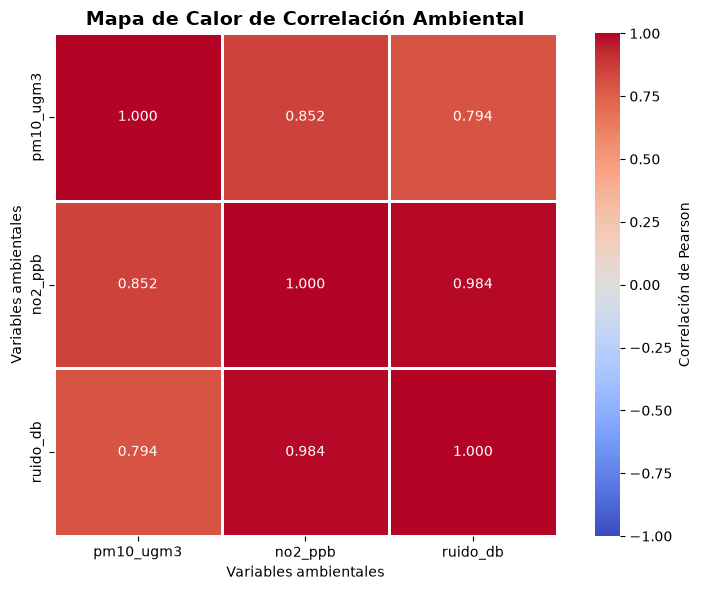

In [6]:
# PASO 6: HEATMAP CON SEABORN

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    fmt=".3f",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Correlación de Pearson"}
)

plt.title(
    "Mapa de Calor de Correlación Ambiental",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Variables ambientales")
plt.ylabel("Variables ambientales")

plt.tight_layout()

# Guardar imagen
plt.savefig(
    "heatmap_seaborn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Celdas visibles: 6


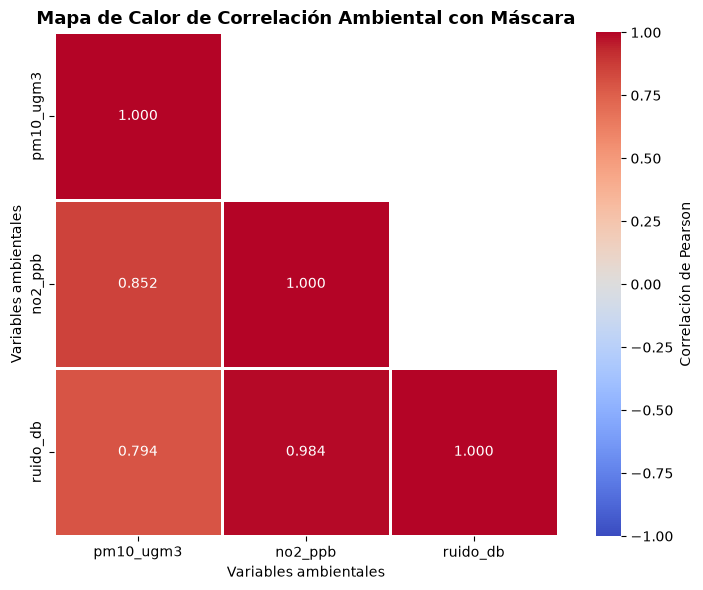

In [7]:
# PASO 7: HEATMAP CON MÁSCARA

# Crear máscara triangular superior
mascara = np.triu(
    np.ones_like(corr, dtype=bool),
    k=1
)

# Contar las celdas visibles
print(
    "Celdas visibles:",
    np.sum(~mascara)
)

# Crear figura
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    mask=mascara,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    fmt=".3f",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Correlación de Pearson"}
)

plt.title(
    "Mapa de Calor de Correlación Ambiental con Máscara",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Variables ambientales")
plt.ylabel("Variables ambientales")

plt.tight_layout()

# Guardar imagen
plt.savefig(
    "heatmap_seaborn_mascara.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()